# Hidden states and transformer beliefs

Follow the talk: **Mess3 → RRXOR → transformer and probe → Mess3 comparison → RRXOR comparison**.

Generate tokens, compute exact HMM beliefs, then compare them with beliefs decoded from a transformer. Each comparison is followed by its interpretation.

In Colab, choose **Runtime → Change runtime type → T4 GPU**, then run the cells in order. The HMM examples also run on CPU.

In [1]:
# Colab already supplies most of these; this cell installs anything missing.
%pip -q install numpy matplotlib ipywidgets torch
import copy, json, math, random, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import ipywidgets as widgets
from IPython.display import display, clear_output, Markdown, Math, HTML
import torch
from torch import nn
from torch.nn import functional as F
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type=='cpu': torch.set_num_threads(min(4,torch.get_num_threads()))
print('Device:', device, '| PyTorch:', torch.__version__)

Device: cuda | PyTorch: 2.14.1+cu130


## 1. HMM notation

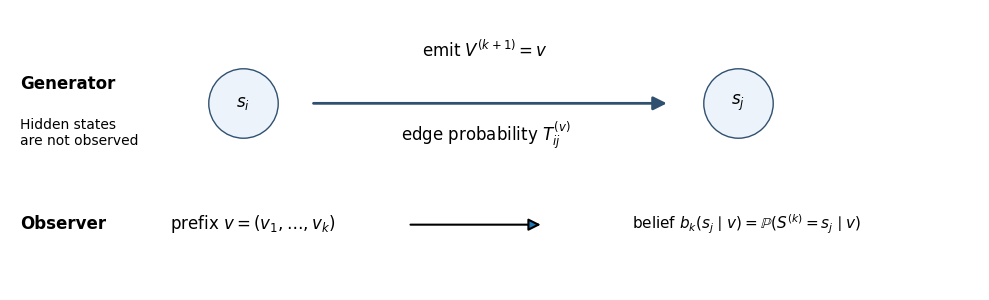

In [2]:
# A visual recap of one HMM transition.
def notation_recap():
    fig, ax = plt.subplots(figsize=(10, 3.1))
    ax.set(xlim=(0, 10), ylim=(0, 3)); ax.axis('off')
    for x,label in [(2.4,r'$s_i$'),(7.5,r'$s_j$')]:
        ax.scatter(x,2,s=2500,c='#edf3fa',edgecolors='#305070',zorder=3)
        ax.text(x,2,label,ha='center',va='center',fontsize=12,zorder=4)
    ax.add_patch(FancyArrowPatch((3.1,2),(6.8,2),arrowstyle='-|>',mutation_scale=20,lw=2,color='#305070'))
    ax.text(4.9,2.5,r'emit $V^{(k+1)}=v$',ha='center',fontsize=12)
    ax.text(4.9,1.6,r'edge probability $T^{(v)}_{ij}$',ha='center',fontsize=12)
    ax.text(.1,2.15,'Generator',ha='left',weight='bold',fontsize=12)
    ax.text(.1,1.55,'Hidden states\nare not observed',ha='left',fontsize=10)
    ax.text(.1,.65,'Observer',weight='bold',fontsize=12)
    ax.text(2.5,.65,r'prefix $v=(v_1,\ldots,v_k)$',ha='center',fontsize=12)
    ax.add_patch(FancyArrowPatch((4.1,.7),(5.5,.7),arrowstyle='-|>',mutation_scale=18,lw=1.5))
    ax.text(7.6,.65,r'belief $b_k(s_j\mid v)=\mathbb{P}(S^{(k)}=s_j\mid v)$',ha='center',fontsize=11)
    fig.tight_layout(); plt.show()
notation_recap()

Circles are hidden states; arrows move between states and emit tokens.

- $\mathcal S=\{s_1,\ldots,s_m\}$: hidden states.
- $\mathcal V$: visible tokens.
- $T^{(u)}_{ij}$: probability of emitting token $u$ and moving from $s_i$ to $s_j$.
- $\mu_0=b_0$: prior over hidden states.

After observing $v=(v_1,\ldots,v_k)$:

$$
b_k=\frac{\mu_0T^{(v_1)}\cdots T^{(v_k)}}{\mu_0T^{(v_1)}\cdots T^{(v_k)}\mathbf1},
\qquad \Gamma_k=b_kE,\qquad E_{iu}=\sum_jT^{(u)}_{ij}.
$$

**$b_k$ gives probabilities of hidden states; $\Gamma_k$ gives probabilities of the next token.** All distributions are row vectors. $\mathbf1$ is a column of ones.

After one more token $u$:

$$
b_{k+1}=\frac{b_kT^{(u)}}{b_kT^{(u)}\mathbf1}.
$$

The denominator is the probability of observing $u$; a zero value means the observation is impossible.

In [3]:
def validate(T):
    T = np.asarray(T, dtype=float)
    if T.ndim != 3 or T.shape[1] != T.shape[2]:
        raise ValueError('Expected shape (number of tokens, number of states, number of states).')
    if not np.isfinite(T).all() or (T < 0).any():
        raise ValueError('Entries must be finite and nonnegative.')
    if not np.allclose(T.sum(axis=(0, 2)), 1, atol=1e-10, rtol=0):
        raise ValueError('For each source state, probabilities over ALL tokens and destinations must sum to 1.')
    return T.copy()

def stationary(T):
    Q = validate(T).sum(axis=0)
    # Reject nonunique stationary priors rather than silently picking one.
    if np.linalg.matrix_rank(Q.T - np.eye(len(Q)), tol=1e-10) != len(Q)-1:
        raise ValueError('Stationary prior is not unique. Choose an irreducible HMM for this workshop.')
    A = np.vstack([Q.T-np.eye(len(Q)), np.ones(len(Q))])
    pi = np.linalg.lstsq(A, np.r_[np.zeros(len(Q)), 1.], rcond=None)[0]
    if pi.min() < -1e-9: raise ValueError('Invalid stationary solution.')
    pi = np.maximum(pi, 0); pi /= pi.sum()
    assert np.allclose(pi @ Q, pi)
    return pi

def mess3(x=.05, a=.85):
    b, y = (1-a)/2, 1-2*x
    return validate([
        [[a*y,b*x,b*x],[a*x,b*y,b*x],[a*x,b*x,b*y]],
        [[b*y,a*x,b*x],[b*x,a*y,b*x],[b*x,a*x,b*y]],
        [[b*y,b*x,a*x],[b*x,b*y,a*x],[b*x,b*x,a*y]]])

def rrxor(p=.5, r=.5):
    T = np.zeros((2,5,5))  # s1=S, s2=0, s3=1, s4=T, s5=F in the original code
    T[0,0,1]=p; T[1,0,2]=1-p
    T[0,1,4]=r; T[1,1,3]=1-r
    T[0,2,3]=r; T[1,2,4]=1-r
    T[1,3,0]=1; T[0,4,0]=1
    return validate(T)

def emission(T): return T.sum(axis=2).T

def filter_history(T, tokens, mu0=None):
    b = stationary(T) if mu0 is None else np.asarray(mu0, dtype=float).copy()
    if (b < 0).any() or not np.isclose(b.sum(),1): raise ValueError('Invalid initial distribution.')
    beliefs, logp = [b.copy()], [0.]
    for v in tokens:
        unnorm = b @ T[int(v)]
        z = unnorm.sum()
        if z <= 0: raise ValueError('Impossible history: posterior is undefined.')
        b = unnorm / z
        beliefs.append(b.copy()); logp.append(logp[-1]+np.log(z))
    return np.array(beliefs), np.array(logp)

def sample(T, length, seed=0, mu0=None):
    rng = np.random.default_rng(seed)
    mu0 = stationary(T) if mu0 is None else np.asarray(mu0)
    s = rng.choice(T.shape[1], p=mu0)
    tokens, states = [], [s]
    for _ in range(length):
        joint = T[:,s,:].reshape(-1)
        index = rng.choice(len(joint), p=joint)
        v,s = divmod(index, T.shape[1])
        tokens.append(v); states.append(s)
    return np.array(tokens, dtype=int), np.array(states)

HMM = {'Mess3':mess3(), 'RRXOR':rrxor()}
ALIASES = {'Mess3':'ABC', 'RRXOR':'01'}  # v1=A or 0, v2=B or 1, v3=C
np.set_printoptions(precision=5, suppress=True)

## 2. Mess3: observe and infer

$\mathcal S=\{s_1,s_2,s_3\}$ and $\mathcal V=\{A,B,C\}$. The matrices specify the edge probabilities.

Choose a **Model**, click **New sample** for 24 tokens, then move **Observed tokens**. The bold prefix is observed; grey tokens are not yet observed. Bars show the belief $b_k$; the next row shows $\Gamma_k$.

- **Standard:** persistent states and informative tokens.
- **More mixing:** states change more often; tokens are less informative.
- **No next-token state information:** every state has the same next-token distribution.

The optional panel lets you enter a history or edit the matrices.

In [4]:
def latex_matrix(A, digits=4):
    A=np.atleast_2d(A)
    rows=[" & ".join(f"{x:.{digits}g}" for x in row) for row in A]
    return r"\begin{pmatrix}"+r" \\ ".join(rows)+r"\end{pmatrix}"

def show_matrices(T):
    display(Math(r"\qquad ".join(
        rf"T^{{(v_{v+1})}}="+latex_matrix(Tv) for v,Tv in enumerate(T))))

def draw_hmm(T, token=None, ax=None):
    if ax is None: _,ax=plt.subplots(figsize=(5,3.6))
    m=T.shape[1]
    if m==5:
        pos=np.array([[-1.3,0],[-.1,.85],[-.1,-.85],[1.25,.85],[1.25,-.85]])
    else:
        pos=np.array([[0,1],[-1,-.65],[1,-.65]])
    for i in range(m):
        for j in range(m):
            active=[v for v in range(len(T)) if T[v,i,j]>0 and (token is None or token==v)]
            if not active: continue
            if i==j:
                start,end=pos[i]+[-.12,.12],pos[j]+[.12,.12]
                rad=-2.3; label=pos[i]+[0,.43]
            else:
                start,end=pos[i],pos[j]; rad=.15
                d=end-start
                label=(start+end)/2+.12*np.array([d[1],-d[0]])
                if m==5:
                    rad=0
                    if i in (3,4) and j==0:
                        sign=1 if i==3 else -1
                        rad=sign*.65
                        label=(start+end)/2+np.array([0,sign*.85])
                    elif (i,j) in [(1,4),(2,3)]:
                        label=start+.30*d+np.array([.08,0])
                    else:
                        label=(start+end)/2+np.array([0,.14 if start[1]+end[1]>=0 else -.14])
            if m==3 and token is None:
                text=','.join(f'$v_{v+1}$' for v in active)
            else:
                text='\n'.join(f'$v_{v+1}:{T[v,i,j]:.3g}$' for v in active)
            ax.add_patch(FancyArrowPatch(start,end,connectionstyle=f'arc3,rad={rad}',
                arrowstyle='-|>',mutation_scale=12,shrinkA=20,shrinkB=20,color='#536779'))
            ax.text(*label,text,ha='center',fontsize=8,
                bbox=dict(facecolor='white',edgecolor='none',alpha=.9))
    ax.scatter(*pos.T,s=850,c='#edf3fa',edgecolors='#305070',zorder=3)
    for i,p in enumerate(pos): ax.text(*p,f'$s_{i+1}$',ha='center',va='center',zorder=4)
    ax.set(xlim=(-1.9,1.9),ylim=(-1.5,1.7),aspect='equal')
    ax.axis('off')
    ax.set_title('Hidden states and emitted tokens',fontsize=11)

EXPLORERS={}
def explorer(name):
    alias=ALIASES[name]; m=HMM[name].shape[1]
    options=(
        [('Standard: strong persistence',(.05,.85)),('More mixing',(.15,.6)),
         ('No next-token state information',(.05,1/3))]
        if name=='Mess3' else
        [('Fair independent bits',(.5,.5)),('First bit biased towards 0',(.75,.5)),
         ('Both bits biased towards 0',(.75,.75))])
    model=widgets.Dropdown(options=options,description='Model:',
                          style={'description_width':'initial'},layout=widgets.Layout(width='350px'))
    new=widgets.Button(description='New sample',icon='refresh')
    k=widgets.IntSlider(value=5,min=0,max=24,description='Observed tokens:',
        continuous_update=False,style={'description_width':'initial'},layout=widgets.Layout(width='500px'))
    matrices=widgets.Output(); view=widgets.Output(); details=widgets.Output(); errors=widgets.Output()
    history=widgets.Text(value='ABAAB' if name=='Mess3' else '00110',description='History:')
    use=widgets.Button(description='Use history')
    fields=[[[widgets.FloatText(value=float(HMM[name][v,i,j]),layout=widgets.Layout(width='78px'))
              for j in range(m)] for i in range(m)] for v in range(len(alias))]
    edit_boxes=[]
    for v in range(len(alias)):
        edit_boxes.extend([widgets.HTML(f'<b>T<sup>(v{v+1})</sup></b> — row = source, column = destination'),
                           widgets.VBox([widgets.HBox(row) for row in fields[v]])])
    apply=widgets.Button(description='Apply entries')
    advanced=widgets.Accordion(children=[
        widgets.VBox([widgets.HBox([history,use]),widgets.HTML('Or edit joint edge probabilities below. '
            'For each source state, sum over every token and destination to get 1.'),
            *edit_boxes,apply,errors]),details],selected_index=None)
    advanced.set_title(0,'Custom history or matrices (optional)')
    advanced.set_title(1,'Joint probabilities and hidden path (optional)')
    state={'seed':10,'ids':None,'states':None,'busy':False}
    def render(*_):
        if state['busy'] or state['ids'] is None: return
        T=HMM[name]; ids=state['ids']; n=min(k.value,len(ids))
        B,lp=filter_history(T,ids[:n]); b=B[-1]; gamma=b@emission(T)
        observed=''.join(alias[v] for v in ids[:n]) or '∅'
        rest=''.join(alias[v] for v in ids[n:])
        with view:
            clear_output(wait=True)
            display(HTML('<div style="font-size:19px;font-family:monospace;margin:8px 0">'
                         +f'<b>{observed}</b><span style="color:#bbc2c8">{rest}</span></div>'))
            fig,axes=plt.subplots(1,2,figsize=(9,3.3))
            draw_hmm(T,ax=axes[0])
            axes[1].bar(range(1,m+1),b,color=plt.cm.Set2(np.linspace(0,1,m)))
            axes[1].set(ylim=(0,1),xticks=range(1,m+1),ylabel='Probability', title=rf'Belief $b_{{{n}}}$ after the bold prefix')
            axes[1].set_xticklabels([f'$s_{i+1}$' for i in range(m)])
            plt.tight_layout(); plt.show()
            display(Math(rf"\Gamma_{{{n}}}=b_{{{n}}}E="+latex_matrix(gamma,3)))
        with details:
            clear_output(wait=True)
            display(Math(r"\mu_0=\pi="+latex_matrix(stationary(T),3)))
            display(Math(rf"q(v)="+latex_matrix(b*np.exp(lp[-1]),4)+
                         rf",\quad p_{{{n}}}(v)={np.exp(lp[-1]):.5g},\quad b_{{{n}}}="+latex_matrix(b,4)))
            if state['states'] is not None:
                display(Math(r"\text{Sampled hidden path: }\quad "+
                    r"\to".join(f"s_{s+1}" for s in state['states'][:n+1])))
    def refresh_matrices():
        with matrices:
            clear_output(wait=True); show_matrices(HMM[name])
    def generate(_=None):
        state['busy']=True; state['seed']+=1
        ids,ss=sample(HMM[name],24,state['seed'])
        state.update(ids=ids,states=ss); k.max=24; k.value=5
        state['busy']=False; render()
    def commit(T):
        T=validate(T)
        if T.shape!=HMM[name].shape: raise ValueError('Keep the same matrix sizes.')
        stationary(T); HMM[name]=T
        for v in range(len(alias)):
            for i in range(m):
                for j in range(m): fields[v][i][j].value=float(T[v,i,j])
        refresh_matrices(); generate()
    def choose(*_):
        a,b=model.value
        commit(mess3(a,b) if name=='Mess3' else rrxor(a,b))
    def safe(fn):
        def callback(_):
            with errors:
                clear_output(wait=True)
                try: fn()
                except Exception as e: print(str(e))
        return callback
    def typed():
        text=history.value.replace(' ','').upper()
        if not text or any(c not in alias for c in text): raise ValueError(f'Use a nonempty history containing only {alias}.')
        ids=np.array([alias.index(c) for c in text],dtype=int)
        filter_history(HMM[name],ids)
        state['busy']=True; state.update(ids=ids,states=None); k.max=len(ids); k.value=len(ids)
        state['busy']=False; render()
    model.observe(choose,names='value'); new.on_click(generate); k.observe(render,names='value')
    use.on_click(safe(typed))
    apply.on_click(safe(lambda:commit(np.array([[[f.value for f in row] for row in grid] for grid in fields]))))
    display(widgets.VBox([widgets.HBox([model,new]),k,matrices,view,advanced]))
    refresh_matrices(); generate()
    EXPLORERS[name]={'model':model,'k':k,'new':new,'history':history,'use':use,
                     'fields':fields,'apply':apply,'state':state,'advanced':advanced}

explorer('Mess3')

## 3. RRXOR: two random bits, then their XOR

Each block is $R_1,R_2,R_1\oplus R_2$. With independent fair bits, the possible blocks are **000, 011, 101, 110**.

$s_1$ is before the first bit; $s_2,s_3$ are before the second; $s_4,s_5$ are before the XOR.

$$b_0=\mu_0=\pi=(\tfrac13,\tfrac16,\tfrac16,\tfrac16,\tfrac16).$$

We start with prior probability **$1/3$ for each phase**: first bit, second bit, or XOR. The first displayed token need not start a block.

Use **New sample** and **Observed tokens** as before. The model menu also offers biased bits. The optional plot illustrates stationarity and time averages: $\pi$ stays unchanged under the hidden-state transition, while a fixed starting state can produce oscillating marginals.

In [5]:
T=HMM['RRXOR']; Q=T.sum(0); pi=stationary(T)
nu=np.array([1.,0,0,0,0]); marginals=[]
for k in range(120):
    marginals.append(nu.copy()); nu=nu@Q
marginals=np.array(marginals)
cesaro=np.cumsum(marginals,axis=0)/np.arange(1,121)[:,None]
_,states=sample(T,12000,seed=12,mu0=np.array([1.,0,0,0,0]))
freq=np.bincount(states,minlength=5)/len(states)

stationary_view=widgets.Output()
with stationary_view:
    fig,ax=plt.subplots(1,2,figsize=(11,3))
    ax[0].plot(marginals[:18,0],'o-',label='P(S^(k)=s1) from s1')
    ax[0].axhline(pi[0],ls='--',c='k',label='π(s1)'); ax[0].legend(); ax[0].set_xlabel('k')
    ax[1].plot(cesaro[:,0],label='Time-averaged marginal for s1')
    ax[1].axhline(pi[0],ls='--',c='k'); ax[1].legend(); ax[1].set_xlabel('Number of times averaged')
    plt.tight_layout(); plt.show()
stationary_panel=widgets.Accordion(children=[stationary_view],selected_index=None)
stationary_panel.set_title(0,'Stationarity and time averages (optional)')
display(stationary_panel)
explorer('RRXOR')

Accordion(children=(Output(),), selected_index=None, _titles={'0': 'Stationarity and time averages (optional)'…

## 4. Draw the exact HMM belief pictures

**No transformer is needed here.** Start at the prior, update the belief with each token, then draw it at the weighted average of the simplex vertices.

$$b_{k+1}=\frac{b_kT^{(v_{k+1})}}{b_kT^{(v_{k+1})}\mathbf1},\qquad z=\sum_i b_i u_i.$$

- **Mess3:** all prefixes of lengths 0–8, including the initial belief: 9,841 endpoints.
- **RRXOR:** all 36 reachable beliefs for the fair stationary model, drawn in a pentagon.

The code uses the standard HMMs, matching the default transformer experiment. Colours come from the exact beliefs. These are the reference pictures we will compare with the transformer later.

In [6]:
# Exact HMM geometry; also reused by the transformer comparison plots.
TRI = np.array([[0,0],[1,0],[.5,np.sqrt(3)/2]])
PENT = np.c_[np.cos(np.linspace(np.pi/2,np.pi/2+2*np.pi,5,endpoint=False)),
             np.sin(np.linspace(np.pi/2,np.pi/2+2*np.pi,5,endpoint=False))]

def enumerate_beliefs(T, depth=8):
    frontier=[stationary(T)]; all_b=[frontier[0]]
    for _ in range(depth):
        nxt=[]
        for b in frontier:
            for Tv in T:
                u=b@Tv
                if u.sum()>0: nxt.append(u/u.sum())
        all_b.extend(nxt); frontier=nxt
    return np.array(all_b)

def geometry(B, ax, title, colors=None, size=3):
    vertices=TRI if B.shape[1]==3 else PENT
    xy=B@vertices
    if colors is None: colors=np.clip(B,0,1) if B.shape[1]==3 else '#456fa8'
    ax.scatter(xy[:,0],xy[:,1],c=colors,s=size,alpha=.65,rasterized=True)
    closed=np.vstack([vertices,vertices[0]])
    ax.plot(*closed.T,c='0.55',lw=1)
    for i,v in enumerate(vertices): ax.text(*(v*1.08+np.array([0,-.025])),f'$s_{i+1}$',ha='center')
    ax.set_aspect('equal'); ax.set_title(title); ax.axis('off')

def mess_cloud(depth=8):
    B=enumerate_beliefs(HMM['Mess3'],depth)
    fig,ax=plt.subplots(figsize=(7,6)); geometry(B,ax,f'Mess3: {len(B):,} history endpoints'); plt.show()


def reachable(T, cap=500, decimals=10):
    B=[stationary(T)]; words=['']; seen={tuple(np.round(B[0],decimals)):0}; cursor=0
    while cursor<len(B):
        b=B[cursor]; word=words[cursor]; cursor+=1
        for v,Tv in enumerate(T):
            u=b@Tv
            if u.sum()<=0: continue
            u/=u.sum(); key=tuple(np.round(u,decimals))
            if key not in seen:
                if len(B)>=cap: return np.array(B),words,False
                seen[key]=len(B); B.append(u); words.append(word+str(v))
    return np.array(B),words,True

RR_B, RR_WORDS, closed=reachable(rrxor())
assert closed and len(RR_B)==36

RR_COLORS=plt.cm.hsv(np.linspace(0,.95,len(RR_B)))
def inspect_rr(index=0):
    fig,ax=plt.subplots(figsize=(7,5))
    geometry(RR_B,ax,'RRXOR: 2D projection of a 4-simplex',RR_COLORS,size=75)
    xy=RR_B@PENT
    ax.scatter(*xy[index],s=250,facecolors='none',edgecolors='black',linewidths=2)
    plt.show()
    print('Index:',index,'| shortest history:',RR_WORDS[index] or '∅')
    print('b =',RR_B[index],'| Γ =',RR_B[index]@emission(rrxor()))

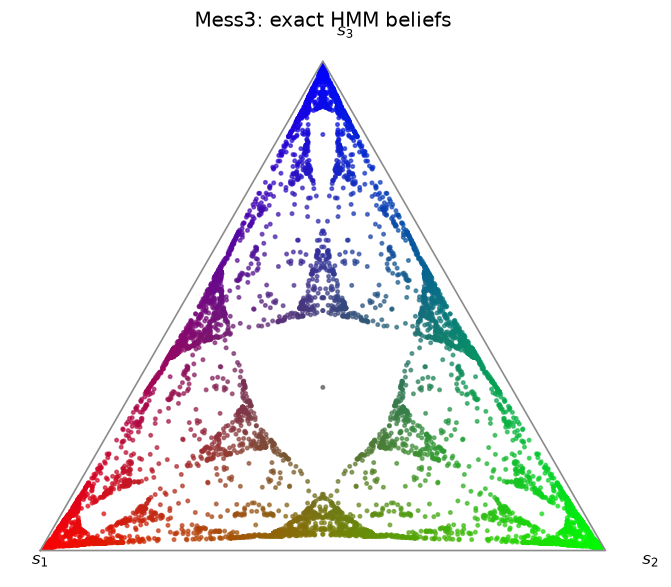

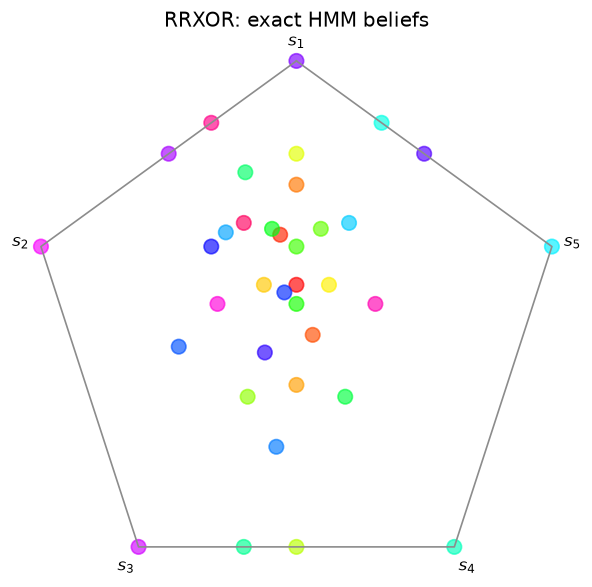

In [ ]:
# Exact reference pictures: run before training the transformer.
EXACT_MESS3 = enumerate_beliefs(mess3(), depth=8)
EXACT_RRXOR, _, complete = reachable(rrxor())
assert complete and len(EXACT_RRXOR) == 36

for name, beliefs, colors in [
    ('Mess3', EXACT_MESS3, np.clip(EXACT_MESS3, 0, 1)),
    ('RRXOR', EXACT_RRXOR, RR_COLORS),
]:
    fig, ax = plt.subplots(figsize=(7, 5))
    geometry(beliefs, ax, f'{name}: exact HMM beliefs', colors,
             size=4 if name == 'Mess3' else 75)
    plt.tight_layout()
    fig.savefig(f'{name.lower()}_exact_hmm_beliefs.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 5. Train on tokens, then probe for beliefs

The transformer is trained only to predict the next token. The HMM beliefs are labels for a **separate analysis step** after training.

For input $v=(v_1,\ldots,v_n)$, block $\ell$ produces

$$X_\theta^{(\ell)}(v)=(x_1^{(\ell)},\ldots,x_n^{(\ell)})\in\mathbb R^{d\times n}.$$

Each position predicts its next token. To predict what follows the whole prefix, take the last column:

$$h_\ell(v)=\pi_nX_\theta^{(\ell)}(v)=x_n^{(\ell)}.$$

$\pi_n$ is a fixed column selector; $L$ is the total number of blocks. We collect residuals **after the MLP residual addition**, before final normalization and unembedding.

Freeze the transformer and fit an affine decoder to exact HMM beliefs:

$$\widehat b(v)^\top=Wh(v)+c,\qquad
\min_{W,c}\sum_v\|Wh(v)+c-b(v)^\top\|^2.$$

Then draw $z=\sum_i\widehat b_i u_i$ using fixed simplex vertices. Predictions can fall outside the simplex.

We use the final block for Mess3 and concatenate all blocks for RRXOR. Probe fitting and evaluation use independent sampled sequences.

In [7]:
class Block(nn.Module):
    def __init__(self,d,heads):
        super().__init__()
        self.ln1=nn.LayerNorm(d); self.ln2=nn.LayerNorm(d)
        self.attn=nn.MultiheadAttention(d,heads,dropout=0.,batch_first=True)
        self.mlp=nn.Sequential(nn.Linear(d,4*d),nn.GELU(),nn.Linear(4*d,d))
    def forward(self,h,mask):
        z=self.ln1(h)
        h=h+self.attn(z,z,z,attn_mask=mask,need_weights=False)[0]
        return h+self.mlp(self.ln2(h))

class TinyTransformer(nn.Module):
    def __init__(self,vocab,context=10,d=128,layers=4,heads=4):
        super().__init__(); self.context=context
        self.token=nn.Embedding(vocab,d); self.position=nn.Embedding(context,d)
        self.blocks=nn.ModuleList([Block(d,heads) for _ in range(layers)])
        self.norm=nn.LayerNorm(d); self.unembed=nn.Linear(d,vocab)
    def forward(self,x,cache=False):
        n=x.shape[1]
        if n>self.context: raise ValueError('Input exceeds context length.')
        h=self.token(x)+self.position(torch.arange(n,device=x.device))[None]
        mask=torch.triu(torch.ones(n,n,device=x.device,dtype=torch.bool),diagonal=1)
        residuals=[]
        for block in self.blocks:
            h=block(h,mask)
            if cache: residuals.append(h)
        logits=self.unembed(self.norm(h))
        return (logits,residuals) if cache else logits

def batch_tokens(T,batch,length,rng):
    # Vectorized joint edge sampling, still emitting from source state before transitioning.
    m=T.shape[1]; states=rng.choice(m,size=batch,p=stationary(T))
    cdf=np.cumsum(T.transpose(1,0,2).reshape(m,-1),axis=1); cdf[:,-1]=1.
    out=np.empty((batch,length),dtype=np.int64)
    for t in range(length):
        indices=(rng.random(batch)[:,None]>cdf[states]).sum(axis=1)
        out[:,t],states=indices//m,indices%m
    return out

def label_batch(T,ids):
    b=np.repeat(stationary(T)[None],len(ids),axis=0); labels=[]
    for t in range(ids.shape[1]):
        b=np.einsum('bi,bij->bj',b,T[ids[:,t]])
        z=b.sum(axis=1,keepdims=True)
        if (z<=0).any(): raise ValueError('Impossible sampled history.')
        b=b/z; labels.append(b.copy())
    return np.stack(labels,axis=1)

@torch.no_grad()
def collect(model,T,ids,chunk=64):
    model.eval(); acts=None; probs=[]
    for i in range(0,len(ids),chunk):
        x=torch.tensor(ids[i:i+chunk],device=device)
        logits,hs=model(x,cache=True)
        if acts is None: acts=[[] for _ in hs]
        for dest,h in zip(acts,hs): dest.append(h.cpu().numpy())
        probs.append(logits.softmax(-1).cpu().numpy())
    return [np.concatenate(a) for a in acts],np.concatenate(probs)

def fit_affine(X,Y,ridge=1e-5):
    # Centering supplies a free intercept. Small ridge stabilizes correlated activations.
    X=torch.as_tensor(X,dtype=torch.float64); Y=torch.as_tensor(Y,dtype=torch.float64)
    xm,ym=X.mean(0),Y.mean(0); xc,yc=X-xm,Y-ym
    gram=xc.T@xc/len(X)+ridge*torch.eye(X.shape[1],dtype=torch.float64)
    W=torch.linalg.solve(gram,xc.T@yc/len(X))
    return W.numpy(),(ym-xm@W).numpy()

def mse(y,p): return float(np.mean((y-p)**2))
def r2(y,p):
    return float(1-np.sum((y-p)**2)/max(np.sum((y-y.mean(0))**2),1e-15))

### Configure and run

Defaults: **1,500 Mess3 updates**, **6,000 RRXOR updates**, batch size 128, context length 10, four blocks, residual dimension 128. **Run all** trains both models.

For a quick rehearsal, set `STEPS={'Mess3':100,'RRXOR':100}`. This checks the workflow; it may not recover the geometry.

`USE_EXPLORER_MATRICES=False` uses the standard HMMs. Set it to `True` to train on your edited models. After changing an HMM, rerun configuration and training.

The optional next-token error is reported as KL divergence in **nats**; smaller is better. This compact experiment may differ from the paper.

In [8]:
STEPS = {'Mess3':1500, 'RRXOR':6000}
BATCH = 128
CONTEXT = 10
PROBE_SEQUENCES = 384
TEST_SEQUENCES = 384
USE_EXPLORER_MATRICES = False
TRAIN_NAMES = ['Mess3','RRXOR']  # Use ['Mess3'] to run only the first experiment.
EXPERIMENT_T = {name:T.copy() for name,T in
                (HMM if USE_EXPLORER_MATRICES else {'Mess3':mess3(),'RRXOR':rrxor()}).items()}

In [9]:
def run_experiment(name,steps=None):
    steps=STEPS[name] if steps is None else steps
    T=EXPERIMENT_T[name].copy(); vocab=len(T)
    torch.manual_seed(SEED)
    model=TinyTransformer(vocab,context=CONTEXT).to(device)
    # Probe-fit and test sequences are independent of transformer-training batches.
    fit_ids=batch_tokens(T,PROBE_SEQUENCES,CONTEXT,np.random.default_rng(200))
    test_full=batch_tokens(T,TEST_SEQUENCES,CONTEXT+1,np.random.default_rng(300))
    test_ids=test_full[:,:CONTEXT]
    Yfit=label_batch(T,fit_ids).reshape(-1,T.shape[1])
    Ytest=label_batch(T,test_ids).reshape(-1,T.shape[1])
    initial_fit,_=collect(model,T,fit_ids); initial_test,_=collect(model,T,test_ids)
    # Initialize and fit a probe on the untrained transformer's representations.
    untrained_X=np.concatenate(initial_fit,axis=-1) if name=='RRXOR' else initial_fit[-1]
    untrained_Z=np.concatenate(initial_test,axis=-1) if name=='RRXOR' else initial_test[-1]
    W0,c0=fit_affine(untrained_X.reshape(-1,untrained_X.shape[-1]),Yfit)
    untrained_pred=untrained_Z.reshape(-1,untrained_Z.shape[-1])@W0+c0
    del initial_fit,initial_test,untrained_X,untrained_Z
    optimizer=torch.optim.AdamW(model.parameters(),lr=3e-4,weight_decay=.01)
    rng=np.random.default_rng(100); losses=[]; started=time.time()
    progress=widgets.IntProgress(value=0,max=steps,description=name)
    display(progress)
    for step in range(1,steps+1):
        model.train()
        full=batch_tokens(T,BATCH,CONTEXT+1,rng)
        x=torch.tensor(full[:,:-1],device=device); y=torch.tensor(full[:,1:],device=device)
        optimizer.zero_grad(set_to_none=True)
        loss=F.cross_entropy(model(x).reshape(-1,vocab),y.reshape(-1))
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.)
        optimizer.step(); losses.append(loss.item())
        if step==1 or step%max(1,steps//10)==0:
            progress.value=step
    model.eval()
    for p in model.parameters(): p.requires_grad_(False)
    Afit,Pfit=collect(model,T,fit_ids); Atest,Ptest=collect(model,T,test_ids)
    Gamma=Ytest@emission(T)
    pred_probs=Ptest.reshape(-1,vocab)
    logP=np.log(np.maximum(pred_probs,1e-12))
    entropy=-np.sum(Gamma*np.log(np.maximum(Gamma,1e-12)),axis=1).mean()
    exact_ce=-np.sum(Gamma*logP,axis=1).mean()
    sampled_ce=-logP[np.arange(len(logP)),test_full[:,1:].reshape(-1)].mean()

    predictions={}; probes={}
    features=[(f'Layer {i+1}',a,z) for i,(a,z) in enumerate(zip(Afit,Atest))]
    features.append(('All layers',np.concatenate(Afit,axis=-1),np.concatenate(Atest,axis=-1)))
    for label,a,z in features:
        X=a.reshape(-1,a.shape[-1]); Z=z.reshape(-1,z.shape[-1])
        W,c=fit_affine(X,Yfit); predictions[label]=Z@W+c; probes[label]=(W,c)
    chosen='All layers' if name=='RRXOR' else f'Layer {len(Afit)}'
    a=features[-1][1] if name=='RRXOR' else Afit[-1]
    z=features[-1][2] if name=='RRXOR' else Atest[-1]
    shuffled=Yfit[np.random.default_rng(400).permutation(len(Yfit))]
    Ws,cs=fit_affine(a.reshape(-1,a.shape[-1]),shuffled)
    predictions['Shuffled labels']=z.reshape(-1,z.shape[-1])@Ws+cs
    predictions['Untrained model']=untrained_pred
    predictions['Mean belief']=np.broadcast_to(Yfit.mean(0),Ytest.shape).copy()
    Wp,cp=fit_affine(Pfit.reshape(-1,vocab),Yfit)
    predictions['Output probabilities (affine)']=pred_probs@Wp+cp
    Wg,cg=fit_affine(Yfit@emission(T),Yfit)
    predictions['Exact next-token Γ (affine)']=Gamma@Wg+cg
    if name=='Mess3' and np.linalg.matrix_rank(emission(T))==3:
        predictions['Output probabilities E⁻¹']=np.linalg.solve(emission(T).T,pred_probs.T).T
    return dict(name=name,T=T,model=model,probes=probes,truth=Ytest,predictions=predictions,
                chosen=chosen,losses=losses,kl=float(exact_ce-entropy),test_ids=test_ids)

RESULTS={}
for name in TRAIN_NAMES:
    RESULTS[name]=run_experiment(name)
display(Markdown("Training complete. Compare the belief pictures below."))


IntProgress(value=0, description='Mess3', max=1500)

IntProgress(value=0, description='RRXOR', max=6000)

Training complete. Compare the belief pictures below.

In [10]:
def exhaustive_mess3(R,depth=8):
    """Evaluate fixed trained probes on every nonempty history up to depth."""
    import itertools
    model=R['model']; T=R['T']; label=R['chosen']
    if depth>model.context: raise ValueError('Exhaustive depth exceeds model context.')
    W,c=R['probes'][label]
    truths=[]; decoded=[]
    for length in range(1,depth+1):
        ids=np.array(list(itertools.product(range(len(T)),repeat=length)),dtype=np.int64)
        activations,_=collect(model,T,ids)
        features=(np.concatenate(activations,axis=-1) if label=='All layers'
                  else activations[int(label.split()[-1])-1])
        truths.append(label_batch(T,ids)[:,-1,:])
        decoded.append(features[:,-1,:]@W+c)
    R['plot_truth']=np.concatenate(truths)
    R['plot_prediction']=np.concatenate(decoded)
    R['plot_prior']=stationary(T)
    assert len(R['plot_truth'])==sum(len(T)**k for k in range(1,depth+1))


def dense_rrxor(R,sequences=10000):
    """Plot more independently sampled contexts with the same frozen model/probe."""
    T=R['T']; model=R['model']; label=R['chosen']
    ids=batch_tokens(T,sequences,model.context,np.random.default_rng(901))
    W,c=R['probes'][label]
    truths=[]; predictions=[]
    for start in range(0,sequences,128):
        batch=ids[start:start+128]
        activations,_=collect(model,T,batch)
        features=(np.concatenate(activations,axis=-1) if label=='All layers'
                  else activations[int(label.split()[-1])-1])
        truths.append(label_batch(T,batch).reshape(-1,T.shape[1]))
        predictions.append(features.reshape(-1,features.shape[-1])@W+c)
    R['plot_truth']=np.concatenate(truths)
    R['plot_prediction']=np.concatenate(predictions)


def belief_colors(T,B):
    if B.shape[1]==3: return np.clip(B,0,1)
    if np.allclose(T,rrxor()):
        # Match exact externally calculated beliefs to the finite MSP registry.
        nearest=((B[:,None,:]-RR_B[None,:,:])**2).sum(-1).argmin(1)
        return RR_COLORS[nearest]
    return np.clip(B@plt.cm.tab10(np.arange(5))[:,:3],0,1)


def show_result(name,probe=None,show=True):
    R=RESULTS[name]; probe=R['chosen'] if probe is None else probe
    dense=probe==R['chosen'] and 'plot_truth' in R
    exhaustive=dense and name=='Mess3'
    B=R['plot_truth'] if dense else R['truth']
    pred=R['plot_prediction'] if dense else R['predictions'][probe]
    colors=belief_colors(R['T'],B)
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    geometry(B,axes[0],f'{name}: exact beliefs',colors,size=4)
    geometry(pred,axes[1],'Transformer reconstruction',colors,size=4)
    if name=='RRXOR' and np.allclose(R['T'],rrxor()):
        groups=((B[:,None,:]-RR_B[None,:,:])**2).sum(-1).argmin(1)
        for group in np.unique(groups):
            selected=groups==group
            for ax,points in [(axes[0],B),(axes[1],pred)]:
                xy=points[selected].mean(0)@PENT
                ax.scatter(*xy,s=95,c=RR_COLORS[group][None],edgecolors='black',
                           linewidths=.7,zorder=5)
    # Identical axis limits make visual comparisons meaningful, including escaped predictions.
    xs=[ax.get_xlim() for ax in axes]; ys=[ax.get_ylim() for ax in axes]
    for ax in axes:
        ax.set_xlim(min(x[0] for x in xs),max(x[1] for x in xs))
        ax.set_ylim(min(y[0] for y in ys),max(y[1] for y in ys))
    plt.tight_layout()
    if show: plt.show()
    return fig

## 6. Mess3: exact beliefs and transformer reconstruction

**Left:** exact HMM beliefs. **Right:** beliefs decoded from the final residual stream.

Each point corresponds to a history of length 1–8. The same true belief sets its colour in both panels.

A belief $b=(b_1,b_2,b_3)$ is drawn at $z=\sum_i b_i u_i$, using fixed triangle vertices. Vertex $u_i$ means certainty about hidden state $s_i$.

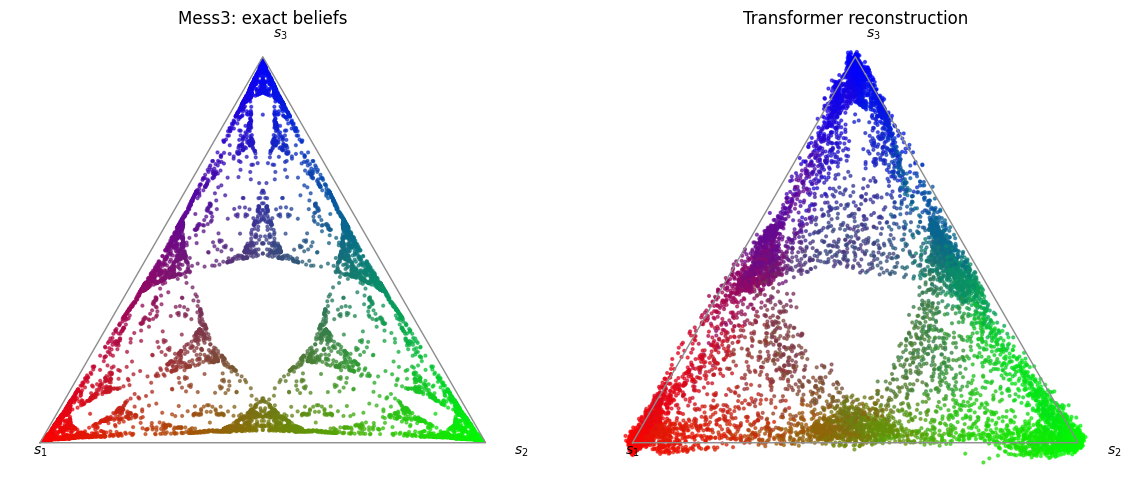

In [11]:
name = 'Mess3'
if name not in RESULTS:
    raise RuntimeError(f'Train {name} above before running its comparison.')
R = RESULTS[name]
exhaustive_mess3(R, depth=8)
fig = show_result(name)
fig.savefig(f'{name.lower()}_belief_reconstruction.png', dpi=180, bbox_inches='tight')
plt.close(fig)

### Mess3: what does reconstruction show?

The transformer learns next-token probabilities:

$$M_\theta(v)\approx\Gamma(v)=b(v)E.$$

Here $\Gamma(v)$ is the true HMM next-token distribution; $b(v)$ is the belief over hidden states.

For standard Mess3,

$$
E\approx\begin{pmatrix}
0.77&0.11&0.11\\
0.11&0.77&0.11\\
0.11&0.11&0.77
\end{pmatrix},\qquad
\boxed{b(v)=\Gamma(v)E^{-1}}.
$$

The displayed entries are rounded; the calculation uses the exact matrix.

**Correct next-token probabilities already contain enough information to recover the belief.** A successful residual probe alone therefore does not establish information beyond the next token.

## 7. RRXOR: exact beliefs and transformer reconstruction

**Left:** exact HMM beliefs. **Right:** beliefs decoded from all layers together.

The comparison uses 10,000 sampled contexts, coloured by their true beliefs. Five belief coordinates are drawn in a pentagon.

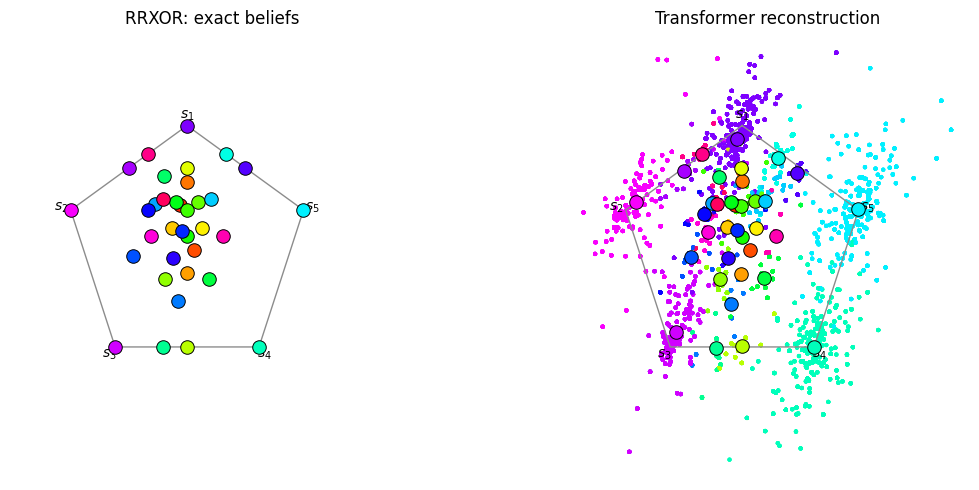

In [13]:
name = 'RRXOR'
if name not in RESULTS:
    raise RuntimeError(f'Train {name} above before running its comparison.')
R = RESULTS[name]
dense_rrxor(R, sequences=10000)
fig = show_result(name)
fig.savefig(f'{name.lower()}_belief_reconstruction.png', dpi=180, bbox_inches='tight')
plt.close(fig)

### RRXOR: no inverse exists

$$
\Gamma(v)=b(v)E,\qquad
E=\begin{pmatrix}
0.50&0.50\\0.50&0.50\\0.50&0.50\\0.00&1.00\\1.00&0.00
\end{pmatrix}.
$$

Before any tokens and after observing 0:

$$\Gamma(\varnothing)=\Gamma(0)=(0.50,0.50),\qquad b(\varnothing)\ne b(0).$$

**The current next-token probabilities do not determine the belief.** We can still compute the belief exactly from the full observed history using the HMM filter.

### Reference

[Shai et al., *Transformers Represent Belief State Geometry in their Residual Stream*](https://arxiv.org/abs/2405.15943).

HMM constructors follow the supplementary code. This notebook is a compact educational experiment.